In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
import statsmodels.formula.api as smf

import os

os.getcwd()

'/Users/henryblake/Desktop/SDS336/SDS336_Project'

In [2]:
loans = pd.read_csv('/Users/henryblake/Desktop/SDS336/loans_full_schema.csv')

In [3]:
loans.shape

(10000, 55)

In [4]:
loans.head()

,emp_title,emp_length,state,homeownership,annual_income,verified_income,debt_to_income,annual_income_joint,verification_income_joint,debt_to_income_joint,...,sub_grade,issue_month,loan_status,initial_listing_status,disbursement_method,balance,paid_total,paid_principal,paid_interest,paid_late_fees
0,global config engineer,3.0,NJ,MORTGAGE,90000.0,Verified,18.01,NaN,NaN,NaN,...,C3,Mar-2018,Current,whole,Cash,27015.86,1999.33,984.14,1015.19,0.0
1,warehouse office clerk,10.0,HI,RENT,40000.0,Not Verified,5.04,NaN,NaN,NaN,...,C1,Feb-2018,Current,whole,Cash,4651.37,499.12,348.63,150.49,0.0
2,assembly,3.0,WI,RENT,40000.0,Source Verified,21.15,NaN,NaN,NaN,...,D1,Feb-2018,Current,fractional,Cash,1824.63,281.80,175.37,106.43,0.0
3,customer service,1.0,PA,RENT,30000.0,Not Verified,10.16,NaN,NaN,NaN,...,A3,Jan-2018,Current,whole,Cash,18853.26,3312.89,2746.74,566.15,0.0
4,security supervisor,10.0,CA,RENT,35000.0,Verified,57.96,57000.0,Verified,37.66,...,C3,Mar-2018,Current,whole,Cash,21430.15,2324.65,1569.85,754.80,0.0


In [5]:
loans.tail()

,emp_title,emp_length,state,homeownership,annual_income,verified_income,debt_to_income,annual_income_joint,verification_income_joint,debt_to_income_joint,...,sub_grade,issue_month,loan_status,initial_listing_status,disbursement_method,balance,paid_total,paid_principal,paid_interest,paid_late_fees
9995,owner,10.0,TX,RENT,108000.0,Source Verified,22.28,NaN,NaN,NaN,...,A4,Jan-2018,Current,whole,Cash,21586.34,2969.80,2413.66,556.14,0.0
9996,director,8.0,PA,MORTGAGE,121000.0,Verified,32.38,NaN,NaN,NaN,...,D3,Feb-2018,Current,whole,Cash,9147.44,1456.31,852.56,603.75,0.0
9997,toolmaker,10.0,CT,MORTGAGE,67000.0,Verified,45.26,107000.0,Source Verified,29.57,...,E2,Feb-2018,Current,fractional,Cash,27617.65,4620.80,2382.35,2238.45,0.0
9998,manager,1.0,WI,MORTGAGE,80000.0,Source Verified,11.99,NaN,NaN,NaN,...,A1,Feb-2018,Current,whole,Cash,21518.12,2873.31,2481.88,391.43,0.0
9999,operations analyst,3.0,CT,RENT,66000.0,Not Verified,20.82,NaN,NaN,NaN,...,B4,Feb-2018,Current,whole,Cash,11574.83,1658.56,1225.17,433.39,0.0


In [6]:
loans.describe()

,emp_length,annual_income,debt_to_income,annual_income_joint,debt_to_income_joint,delinq_2y,months_since_last_delinq,earliest_credit_line,inquiries_last_12m,total_credit_lines,...,public_record_bankrupt,loan_amount,term,interest_rate,installment,balance,paid_total,paid_principal,paid_interest,paid_late_fees
count,9183.000000,1.000000e+04,9976.000000,1.495000e+03,1495.000000,10000.00000,4342.000000,10000.00000,10000.00000,10000.000000,...,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,5.930306,7.922215e+04,19.308192,1.279146e+05,19.979304,0.21600,36.760709,2001.29000,1.95820,22.679600,...,0.123800,16361.922500,43.272000,12.427524,476.205323,14458.916610,2494.234773,1894.448466,599.666781,0.119516
std,3.703734,6.473429e+04,15.004851,7.016838e+04,8.054781,0.68366,21.634939,7.79551,2.38013,11.885439,...,0.337172,10301.956759,11.029877,5.001105,294.851627,9964.561865,3958.230365,3884.407175,517.328062,1.813468
min,0.000000,0.000000e+00,0.000000,1.920000e+04,0.320000,0.00000,1.000000,1963.00000,0.00000,2.000000,...,0.000000,1000.000000,36.000000,5.310000,30.750000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2.000000,4.500000e+04,11.057500,8.683350e+04,14.160000,0.00000,19.000000,1997.00000,0.00000,14.000000,...,0.000000,8000.000000,36.000000,9.430000,256.040000,6679.065000,928.700000,587.100000,221.757500,0.000000
50%,6.000000,6.500000e+04,17.570000,1.130000e+05,19.720000,0.00000,34.000000,2003.00000,1.00000,21.000000,...,0.000000,14500.000000,36.000000,11.980000,398.420000,12379.495000,1563.300000,984.990000,446.140000,0.000000
75%,10.000000,9.500000e+04,25.002500,1.515455e+05,25.500000,0.00000,53.000000,2006.00000,3.00000,29.000000,...,0.000000,24000.000000,60.000000,15.050000,644.690000,20690.182500,2616.005000,1694.555000,825.420000,0.000000
max,10.000000,2.300000e+06,469.090000,1.100000e+06,39.980000,13.00000,118.000000,2015.00000,29.00000,87.000000,...,3.000000,40000.000000,60.000000,30.940000,1566.590000,40000.000000,41630.443684,40000.000000,4216.440000,52.980000


In [7]:
loans.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 55 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   emp_title                         9167 non-null   str    
 1   emp_length                        9183 non-null   float64
 2   state                             10000 non-null  str    
 3   homeownership                     10000 non-null  str    
 4   annual_income                     10000 non-null  float64
 5   verified_income                   10000 non-null  str    
 6   debt_to_income                    9976 non-null   float64
 7   annual_income_joint               1495 non-null   float64
 8   verification_income_joint         1455 non-null   str    
 9   debt_to_income_joint              1495 non-null   float64
 10  delinq_2y                         10000 non-null  int64  
 11  months_since_last_delinq          4342 non-null   float64
 12  earliest_credit_

In [8]:
loans.isnull().sum()

emp_title                            833
emp_length                           817
state                                  0
homeownership                          0
annual_income                          0
verified_income                        0
debt_to_income                        24
annual_income_joint                 8505
verification_income_joint           8545
debt_to_income_joint                8505
delinq_2y                              0
months_since_last_delinq            5658
earliest_credit_line                   0
inquiries_last_12m                     0
total_credit_lines                     0
open_credit_lines                      0
total_credit_limit                     0
total_credit_utilized                  0
num_collections_last_12m               0
num_historical_failed_to_pay           0
months_since_90d_late               7715
current_accounts_delinq                0
total_collection_amount_ever           0
current_installment_accounts           0
accounts_opened_

In [9]:
# Drop unneccessary columns
loans = loans.drop(['emp_title', 'verified_income', 'verification_income_joint'], axis = 1)

In [10]:
# Turn employee length into category since it caps out at 10
loans['emp_length'] = loans['emp_length'].astype('category')

In [11]:
# Creates a total income feature thats either joint income or solo depending on joint status
loans['total_income'] = loans['annual_income_joint'].fillna(loans['annual_income'])
loans = loans.drop(['annual_income', 'annual_income_joint'], axis = 1)

In [12]:
# Creates a total debt to income income feature thats either joint income or solo depending on joint status
loans['total_debt_to_income'] = loans['debt_to_income_joint'].fillna(loans['debt_to_income'])
loans = loans.drop(['debt_to_income', 'debt_to_income_joint'], axis = 1)

In [13]:
# Impute functions
def impute_median(feature):
    loans[feature] = loans[feature].fillna(loans[feature].median())

def impute_mode(feature):
    loans[feature] = loans[feature].fillna(loans[feature].mode()[0])

def impute_high(feature):
    loans[feature] = loans[feature].fillna(loans[feature].max() + 1)

In [14]:
# Recheck missing values
loans.isnull().sum()

emp_length                           817
state                                  0
homeownership                          0
delinq_2y                              0
months_since_last_delinq            5658
earliest_credit_line                   0
inquiries_last_12m                     0
total_credit_lines                     0
open_credit_lines                      0
total_credit_limit                     0
total_credit_utilized                  0
num_collections_last_12m               0
num_historical_failed_to_pay           0
months_since_90d_late               7715
current_accounts_delinq                0
total_collection_amount_ever           0
current_installment_accounts           0
accounts_opened_24m                    0
months_since_last_credit_inquiry    1271
num_satisfactory_accounts              0
num_accounts_120d_past_due           318
num_accounts_30d_past_due              0
num_active_debit_accounts              0
total_debit_limit                      0
num_total_cc_acc

In [15]:
# Define current late payments
loans['had_late_payments'] = np.where((loans['loan_status'] == 'Late (31-120 days)') | 
                                (loans['loan_status'] == 'Late (16-30 days)') | 
                                (loans['loan_status'] == 'Charged Off'), 1, 0)

In [16]:
# Define if they paid late fees
loans['had_late_fees'] = np.where(loans['paid_late_fees'] > 0, 1, 0)

In [17]:
# Define delinquency
loans['delinquency'] = np.where(loans['had_late_payments'] + loans['had_late_fees'] > 0, 1, 0)

In [18]:
# Delinquency count
loans['delinquency'].value_counts()

delinquency
0    9851
1     149
Name: count, dtype: int64

In [19]:
# Select features for correlation
# NEEDS ATTENTION
loans = loans[[
    'emp_length',
    'state',
    'homeownership',
    'delinq_2y',
    'months_since_last_delinq',
    'earliest_credit_line',
    'inquiries_last_12m',
    'total_credit_lines',
    'open_credit_lines',
    'total_credit_limit',
    'total_credit_utilized',
    'num_collections_last_12m',
    'num_historical_failed_to_pay',
    'months_since_90d_late',
    'current_accounts_delinq',
    'total_collection_amount_ever',
    'current_installment_accounts',
    'accounts_opened_24m',
    'months_since_last_credit_inquiry',
    'num_satisfactory_accounts',
    'num_accounts_120d_past_due',
    'num_accounts_30d_past_due',
    'num_active_debit_accounts',
    'total_debit_limit',
    'num_total_cc_accounts',
    'num_open_cc_accounts',
    'num_cc_carrying_balance',
    'num_mort_accounts',
    'account_never_delinq_percent',
    'tax_liens',
    'public_record_bankrupt',
    'loan_purpose',
    'application_type',
    'loan_amount',
    'term',
    'issue_month',
    'initial_listing_status',
    'disbursement_method',
    'total_income',
    'total_debt_to_income',
    'delinquency']]

In [21]:
# variable correlations
correlations = loans.corr(numeric_only = True)['delinquency'].sort_values(ascending = False)
correlations = correlations.drop(['delinquency', 'num_accounts_120d_past_due'])
print(correlations)

term                                0.028473
inquiries_last_12m                  0.027477
earliest_credit_line                0.012896
account_never_delinq_percent        0.003498
total_income                        0.003342
accounts_opened_24m                 0.003126
loan_amount                         0.002580
num_collections_last_12m           -0.000367
months_since_90d_late              -0.000457
public_record_bankrupt             -0.001092
current_accounts_delinq            -0.001230
num_accounts_30d_past_due          -0.001230
delinq_2y                          -0.001430
tax_liens                          -0.003408
num_historical_failed_to_pay       -0.003478
current_installment_accounts       -0.004183
total_collection_amount_ever       -0.004921
total_credit_limit                 -0.007505
total_credit_utilized              -0.007970
total_debit_limit                  -0.013275
total_debt_to_income               -0.014139
months_since_last_delinq           -0.017277
num_mort_a

In [86]:
palette = ['#D6F56B', '#3FB8AF']

Text(0.5, 1.0, 'Number of Delinquent vs. Non-Delinquent loans')

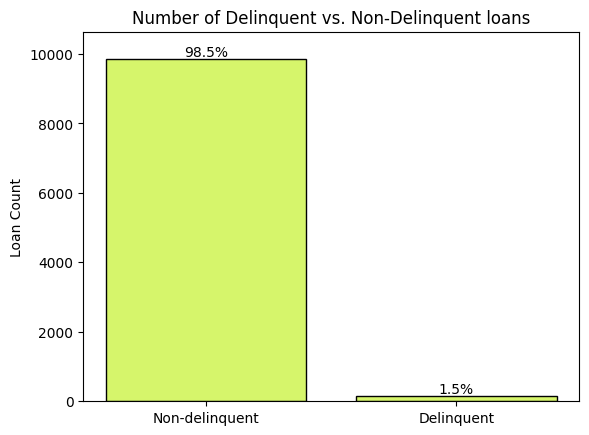

In [87]:
counts = loans['delinquency'].value_counts()
labels = counts.index.map({0: 'Non-delinquent', 1: 'Delinquent'})
bars = plt.bar(labels, counts.values, color = palette[0], edgecolor = 'black')
pcts = counts.values / counts.values.sum()
plt.bar_label(bars, labels=[f'{p:.1%}' for p in pcts])
plt.ylabel('Loan Count')
plt.margins(y=0.08)
plt.title('Number of Delinquent vs. Non-Delinquent loans')

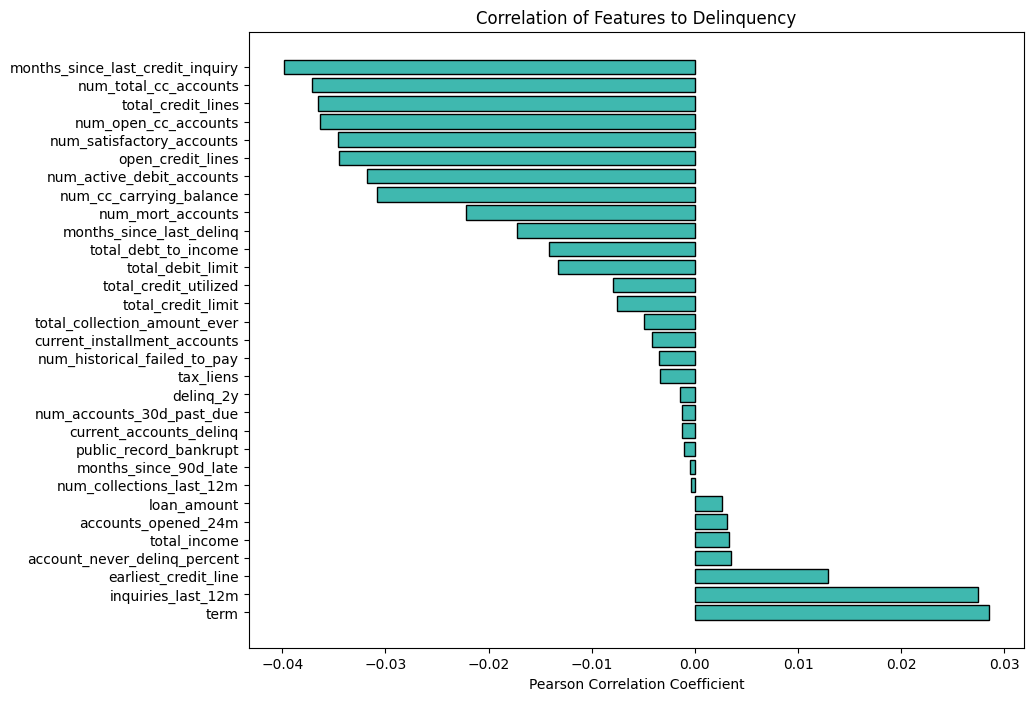

In [88]:
plt.figure(figsize=(10, 8))
plt.barh(correlations.index, correlations.values, edgecolor = 'black', color = palette[1])
plt.yticks(fontsize = 10)
plt.xlabel('Pearson Correlation Coefficient')
plt.title('Correlation of Features to Delinquency')
plt.show()

In [89]:
loans['term'].value_counts()

term
36    6970
60    3030
Name: count, dtype: int64

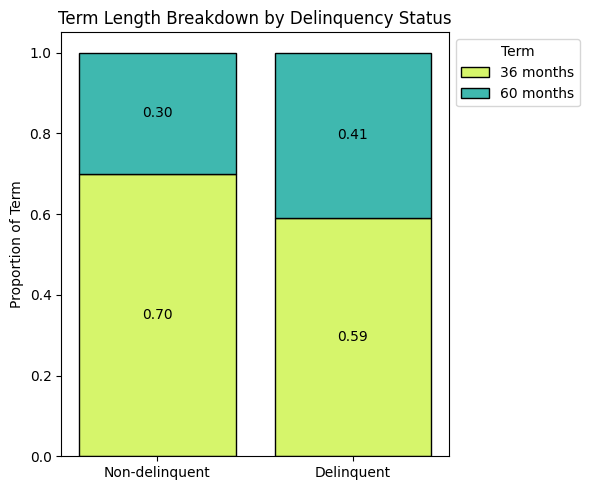

In [90]:
props = pd.crosstab(loans['delinquency'], loans['term'], normalize='index')
props.index = props.index.map({0: 'Non-delinquent', 1: 'Delinquent'})

fig, ax = plt.subplots(figsize=(6, 5))
bars1 = ax.bar(props.index, props[36], label='36 months', color=palette[0], edgecolor='black')
bars2 = ax.bar(props.index, props[60], bottom=props[36], label='60 months', color=palette[1], edgecolor='black')

ax.bar_label(bars1, fmt='%.2f', label_type='center')
ax.bar_label(bars2, fmt='%.2f', label_type='center')
ax.set_ylabel('Proportion of Term')
ax.set_title('Term Length Breakdown by Delinquency Status')
ax.legend(title='Term', loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

In [ ]:
# # Define X and Y
# X = loans.drop(['delinquency'], axis = 1)
# y = loans['delinquency']

In [ ]:
# # Train test split
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = .2, random_state = 42)

# # Encode categorical variables
# X_train = pd.get_dummies(X_train, drop_first = True)
# X_test = pd.get_dummies(X_test, drop_first = True)

# X_train, X_test = X_train.align(
#     X_test, join='left', axis=1, fill_value = 0
# )

In [ ]:
# # Fit random forest model
# rf_model = RandomForestClassifier(random_state = 42)

# rf_scores = cross_val_score(
#     rf_model,
#     X_train,
#     y_train,
#     cv = 5,
#     scoring = "average_precision"
# )

# print("Fold scores:", rf_scores)
# print("Mean score:", rf_scores.mean())

In [ ]:
# # Fit XGBoost model
# xgb_model = XGBClassifier(random_state=42)

# xgb_scores = cross_val_score(
#     xgb_model,
#     X_train,
#     y_train,
#     cv = 5,
#     scoring = "average_precision"
# )

# print("Fold scores:", xgb_scores)
# print("Mean score:", xgb_scores.mean())